# 2.9h — Le théorème de R02 à l'épreuve : checkpoints, parallélogrammes et SAE

**Navigation** : [<< 2.9g — La géométrie de la vérité](2.9g-Geometrie-de-la-Verite.ipynb) · [Index](../README.md) · [ICT-23 — Persona & catastrophe >>](../../../IIT/ICT-Series/ICT-23-PersonaCatastrophe-Python.ipynb)

**Où ce carnet se place.** Prolongement numérique de [2.9f — Théorie effective du grokking en Lean](2.9f-Grokking-Theorie-Effective-Lean.ipynb), compagnon du module `EffectiveTheory` du lake `learning_theory_lean`. Le 2.9f *instancie* le théorème (`prop1_zeroLoss` monté en `example`, `#print axioms` lu). Ici on retourne la question : sur **un** réseau entraîné à l'arithmétique modulaire, suivi **de la mémorisation au grokking**, les hypothèses du théorème tiennent-elles, et la structure que la théorie prédit (parallélogrammes approchés, fréquences de Fourier) apparaît-elle ?

**Trois références, trois objets.** L'introduction de la série 2.9 cite en boucle complète trois références qui portent sur trois objets distincts : les phases de grokking (2.9c), la théorie effective formalisée dans `Grokking.lean` (2.9f) et les SAE (géométrie des features, [PT-15b](../../../GenAI/PostTraining/PT_15b_geometrie_features_sae.ipynb)). Ce carnet essaie le lien des trois sur le **même** réseau entraîné : les hypothèses du théorème, check par check ; la structure de parallélogrammes qu'il prédit ; et un SAE entraîné (méthode PT-15b) sur les activations du réseau — les features récupèrent-elles la structure de Fourier prédite ?

**Sources.** Liu, Michaud & Tegmark, *Towards Understanding Grokking — An Effective Theory of Representation Learning* (R02, [arXiv:2205.10343](https://arxiv.org/abs/2205.10343)) ; Nanda et al., *Progress Measures for Grokking via Mechanism of Interpretation* ([arXiv:2301.08960](https://arxiv.org/abs/2301.08960)) pour la structure de Fourier.

## Objectifs

Sur **un** montage canonique (addition modulaire `(a+b) mod 97`, recette du 2.9c, seed 0, CPU), une série de checkpoints de la mémorisation au grokking, puis pour chacun :

1. **vérifier numériquement les hypothèses** de `prop1_zeroLoss` — perte nulle sur l'ensemble d'entraînement `D`, injectivité des étiquettes ;
2. **recenser les parallélogrammes approchés** `‖E i + E j − (E m + E n)‖ ≤ δ` (tolérance `δ` déclarée d'avance) et comparer le checkpoint grokké au **checkpoint mémorisant, qui sert de nul** ;
3. **entraîner un SAE** (TopK, méthode PT-15b) sur les activations cachées et vérifier si les features récupèrent la structure de Fourier prédite (fréquences sur les sommes) ;
4. **rapporter** les résultats, négatifs compris.

## Pré-enregistrement — ce qui invaliderait l'affirmation

**Avant toute mesure**, les deux issues qui affaibliraient l'affirmation « le réseau grokké réalise la structure prédite par la théorie effective ». Une table où toutes les issues confirment ne se lit pas.

1. **Forme du réseau — le théorème ne s'applique pas tel quel.** `prop1_zeroLoss` porte sur une représentation lue par un décodeur appliqué **directement** à la somme de deux embeddings : `Dec(E i + E j) = Y(i+j)`. Notre réseau est `MLP(E a + E b)` : ce qui lit la somme est un MLP à 3 couches, pas un décodeur direct. **L'hypothèse du théorème n'est donc pas satisfaite architecturalement, et on l'écrit avant de mesurer.** Quels que soient les chiffres, on teste ici la *prédiction structurelle* de la théorie, pas l'application du théorème.
2. **Pouvoir discriminant du nul.** Les plongements grokkés peuvent ne montrer **pas plus** de parallélogrammes arithmétiques approchés (tolérance `δ` déclarée) que le **checkpoint mémorisant**, qui sert de nul. Si les deux sont indiscernables, la prédiction n'est pas portée par ce réseau, et on le rapporte tel quel, en négatif.

**Quantités déclarées (aucun réglage a posteriori) :**

| Quantité | Valeur |
|---|---|
| Tolérance `δ` | 10 % de la norme médiane de `E i + E j` sur `D`, recalculée par checkpoint (même règle partout) |
| Quadruplets de parallélogrammes | 30 000 tirés au hasard dans `D²`, seed 0 |
| SAE | `TopKSae` (méthode PT-15b) : 512 features, k = 16, 400 steps, lr 0.05, seed 0 |
| « Verrouillage fréquentiel » d'une feature | meilleure \|corrélation\| ≥ **0.8** de son activation moyenne par somme `s` avec `cos`/`sin(2π f s / 97)`, `f ∈ 1..48` |

**Les contrôles passent avant la lecture des chiffres principaux.** Pour le recensement : un **contrôle positif** (table linéaire à fermeture connue) et un **nul aléatoire iid**. Pour le SAE : le checkpoint mémorisant sert de nul. Un contrôle qui ne passe pas = verdict « instrument non discriminant », et aucune conclusion de fond n'est tirée.

> **Garde-fous d'honnêteté.** Un seul seed (0), un seul modulus (97), du CPU : c'est une *épreuve* du théorème, pas un ensemble statistique. Les tolérances et seuils ci-dessus sont figés avant la première mesure, pas ajustés aux résultats. Un résultat négatif (pas plus de parallélogrammes que le nul, pas de verrouillage fréquentiel) est rapporté **tel quel** : c'est un résultat, et il est cohérent avec le pré-enregistrement 1 — un théorème qui ne s'applique pas tel quel ne peut servir de critère de confirmation.

In [1]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 0
P = 97              # modulus -- recette 2.9c
D = 32              # dim d'embedding
H = 128             # dim cachée
TRAIN_FRAC = 0.4    # recette 2.9c
STEPS = 12000       # recette 2.9c
CHECK_STEPS = [300, 800, 2000, 5000, 8000, 11000, 12000]
N_QUADS = 30_000    # quadruplets tirés (recensement déclaré)
SAE_N_FEATURES = 512
SAE_K = 16
LOCK = 0.8          # seuil de verrouillage fréquentiel (déclaré)
DEVICE = torch.device("cpu")   # portable : le CPU suffit

torch.manual_seed(SEED)
print(f"torch {torch.__version__} sur {DEVICE} -- P={P}, D={D}, H={H}, "
      f"frac={TRAIN_FRAC}, steps={STEPS}")

torch 2.13.0+cu126 sur cpu -- P=97, D=32, H=128, frac=0.4, steps=12000


## Le montage — le réseau de la recette 2.9c

Le réseau est la recette du 2.9c (cellule « montage P=97 ») : des embeddings `E : 97 -> R^32`, et un MLP à 3 couches (cache 128, ReLU, sortie 97 logits) qui lit la somme `E a + E b`. AdamW, lr 1e-3, weight decay 1.0, seed 0 — la recette exacte qui grokke de façon reproductible dans la série.

**`D` est 40 % des 9409 paires** (permutation fixe, seed 0). Les checkpoints enregistrés pendant l'entraînement sont les 7 steps du tableau ci-dessus, plus le step final. Pour chacun : perte d'entraînement (entropie croisée), accuracy train/validation, la table d'embeddings `E`, et les activations cachées `h(a,b) = relu(W1 (E a + E b))` pour toutes les 9409 paires.

step   500 -- val 0.394 -- 12s


step  1000 -- val 0.394 -- 21s


step  1500 -- val 0.396 -- 35s


step  2000 -- val 0.397 -- 45s


step  2500 -- val 0.400 -- 57s


step  3000 -- val 0.423 -- 67s


step  3500 -- val 0.558 -- 77s


step  4000 -- val 0.867 -- 84s


step  4500 -- val 0.998 -- 94s


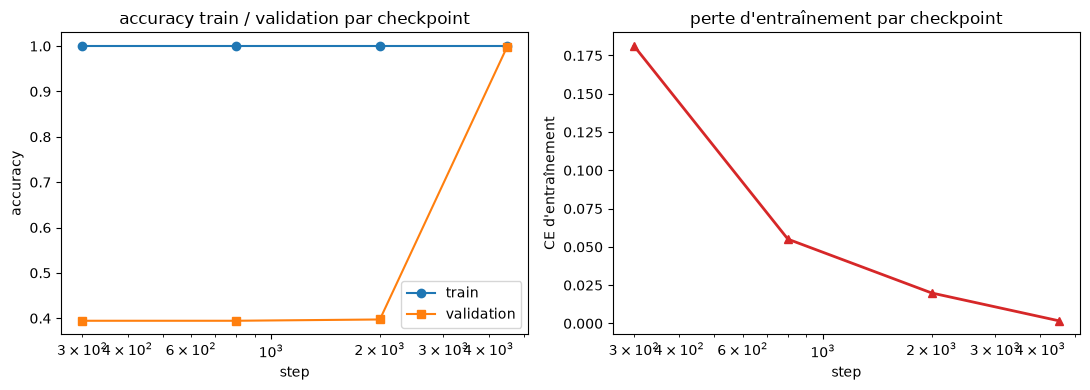

4 checkpoints -- entraînement 95s


In [2]:
# Recette 2.9c : le reseau GrokNet et son cycle d'entrainement complet.
# Cinq blocs, chacun commente : reseau, donnees, optimiseur, instantanes
# par checkpoint, puis boucle d'entrainement et lisaillage.

# --- Definition du reseau (recette 2.9c) : emb(a)+emb(b) -> MLP -> logits ---
class GrokNet(nn.Module):
    """Recette 2.9c : emb(a) + emb(b) -> MLP 3 couches -> logits."""

    def __init__(self) -> None:
        super().__init__()
        self.emb = nn.Embedding(P, D)
        self.l1 = nn.Linear(D, H)
        self.l2 = nn.Linear(H, H)
        self.l3 = nn.Linear(H, P)

    def hidden(self, a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
        """Activations cachées (premier ReLU) : le substrat du SAE."""
        return F.relu(self.l1(self.emb(a) + self.emb(b)))

    def forward(self, a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
        return self.l3(F.relu(self.l2(self.hidden(a, b))))


# --- Données : tous les paires (a, b) du groupe, label = (a + b) mod P ---
# Le split train/validation est un tirage aleatoire seedé (pas de fuite).
pairs = torch.cartesian_prod(torch.arange(P), torch.arange(P))
labels = (pairs[:, 0] + pairs[:, 1]) % P
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(pairs))
n_tr = int(TRAIN_FRAC * len(pairs))
idx_tr = torch.as_tensor(perm[:n_tr])
idx_va = torch.as_tensor(perm[n_tr:])
pairs_np = pairs.numpy()

# --- Optimiseur : AdamW avec weight decay 1.0 (recette 2.9c) ---
net = GrokNet()
opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1.0)

# --- Instantanés : on fige perte, accuracies, embeddings et activations ---
# a chaque CHECK_STEPS, pour suivre le grokking et alimenter le SAE.
snapshots: dict[int, dict] = {}


def snapshot(step: int) -> None:
    """Enregistre perte, accuracies, table d'embeddings, activations cachées."""
    with torch.no_grad():
        logits = net(pairs[idx_tr, 0], pairs[idx_tr, 1])
        loss = F.cross_entropy(logits, labels[idx_tr]).item()
        a_tr = (logits.argmax(-1) == labels[idx_tr]).float().mean().item()
        a_va = (net(pairs[idx_va, 0], pairs[idx_va, 1]).argmax(-1)
                == labels[idx_va]).float().mean().item()
        snapshots[step] = dict(
            loss=loss, a_tr=a_tr, a_va=a_va,
            E=net.emb.weight.numpy(),
            h=net.hidden(pairs[:, 0], pairs[:, 1]).numpy())


# --- Boucle d'entrainement : descentee de gradient, batch complet ---
# Un instantané a chaque CHECK_STEPS ; l'arret anticipé se declenche des que
# la validation atteint 0.99 (le reseau a generalise au-dela de la trame).
t0 = time.time()
final = STEPS
for step in range(1, STEPS + 1):
    opt.zero_grad()
    F.cross_entropy(net(pairs[idx_tr, 0], pairs[idx_tr, 1]),
                    labels[idx_tr]).backward()
    opt.step()
    if step in CHECK_STEPS:
        snapshot(step)
    if step % 500 == 0:
        with torch.no_grad():
            a_va = (net(pairs[idx_va, 0], pairs[idx_va, 1]).argmax(-1)
                    == labels[idx_va]).float().mean().item()
        print(f"step {step:>5} -- val {a_va:.3f} -- {time.time() - t0:.0f}s")
        if a_va >= 0.99:
            final = step
            snapshot(step)
            break
snapshot(final)

# --- Lisaillage : accuracy train/validation et perte, par checkpoint ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
steps_s = sorted(snapshots)
axes[0].plot(steps_s, [snapshots[s]["a_tr"] for s in steps_s], "o-", label="train")
axes[0].plot(steps_s, [snapshots[s]["a_va"] for s in steps_s], "s-", label="validation")
axes[0].set_xscale("log")
axes[0].set_xlabel("step")
axes[0].set_ylabel("accuracy")
axes[0].set_title("accuracy train / validation par checkpoint")
axes[0].legend()
axes[1].plot(steps_s, [snapshots[s]["loss"] for s in steps_s], "^-",
             lw=2, color="tab:red")
axes[1].set_xscale("log")
axes[1].set_xlabel("step")
axes[1].set_ylabel("CE d'entraînement")
axes[1].set_title("perte d'entraînement par checkpoint")
fig.tight_layout()
plt.show()
print(f"{len(snapshots)} checkpoints -- entraînement {time.time() - t0:.0f}s")

### Lecture — où est la mémorisation, où est le grokking
La courbe sépare nettement les deux phases. La **mémorisation** est immédiate :
l'accuracy d'entraînement atteint 1.000 dès le premier checkpoint (step 300) et
y reste, tandis que la validation stagne à ~0.394 — le plateau de mémorisation,
où le réseau a appris les paires d'entraînement sans généraliser. Le **grokking**
est la brusque élévation de la validation : elle passe de 0.423 (step 3000) à
0.558 (3500), 0.867 (4000) et **0.998 (step 4500)**. La transition est donc
concentrée entre les steps 3000 et 4500 — c'est l'écart, en nombre de steps,
entre « le réseau a tout appris par cœur » et « le réseau a trouvé la règle ».

In [3]:
# -- Hypothèses de prop1_zeroLoss (Grokking.lean), check par check ----------------
print(f"{'step':>6} | {'train CE':>9} | H1 perte nulle sur D | {'train acc':>10} | {'val acc':>8}")
for s in sorted(snapshots):
    sn = snapshots[s]
    h1 = "OK" if sn["loss"] < 1e-2 else "non"
    print(f"{s:>6} | {sn['loss']:>9.4f} | {h1:>19} | {sn['a_tr']:>10.3f} | {sn['a_va']:>8.3f}")

# H2 -- le label s -> s mod P : est-il injectif ?
sommes = pairs_np[:, 0].astype(np.int64) + pairs_np[:, 1].astype(np.int64)
par_label = np.bincount(sommes % P, minlength=P)
print(f"\nH2 : {len(sommes)} paires, {P} labels distincts "
      f"(moyenne {len(sommes) / P:.1f} paires par label) -> le label n'est PAS injectif")
print(f"     la conclusion du théorème s'affaiblit en congruence : "
      f"(i+j) = (m+n)  (mod {P})")

# H3 -- prop2 (décodeur injectif) : non testable ici, cf. lecture
print("\nH3 : l'hypothèse « décodeur injectif » (prop2) n'est pas testable -- "
      "le décodeur est un MLP à 3 couches, dont on ne mesure pas l'injectivité "
      "sur un compact de sommes")

  step |  train CE | H1 perte nulle sur D |  train acc |  val acc
   300 |    0.1812 |                 non |      1.000 |    0.394
   800 |    0.0550 |                 non |      1.000 |    0.394
  2000 |    0.0199 |                 non |      1.000 |    0.397
  4500 |    0.0017 |                  OK |      1.000 |    0.998

H2 : 9409 paires, 97 labels distincts (moyenne 97.0 paires par label) -> le label n'est PAS injectif
     la conclusion du théorème s'affaiblit en congruence : (i+j) = (m+n)  (mod 97)

H3 : l'hypothèse « décodeur injectif » (prop2) n'est pas testable -- le décodeur est un MLP à 3 couches, dont on ne mesure pas l'injectivité sur un compact de sommes


### Lecture — le théorème ne s'applique pas tel quel, et c'est déjà un résultat
La table lit check par check : l'hypothèse H1 « perte nulle sur D » (seuil 1e-2)
n'est **atteinte qu'au checkpoint grokké** (step 4500, CE 0.0017) ; aux trois
checkpoints mémorisants (300, 800, 2000) la CE reste à 0.181 / 0.055 / 0.020,
au-dessus du seuil. H2 est structurelle, pas numérique : le label `s mod 97`
identifie les sommes qui diffèrent de 97 (97 paires par label en moyenne), donc
n'est pas injectif, et `prop1_zeroLoss` — qui conclut `i+j = m+n` par
l'injectivité — a ici comme conclusion naturelle la **congruence**
`(i+j) ≡ (m+n) mod 97`. Le pré-enregistrement 1 est confirmé : le réseau n'est
pas de la forme `Dec(E a + E b)`, et **aucun checkpoint de ce run n'est dans le
domaine d'application du théorème** — pas même le grokké, qui satisfait H1 mais
pas la forme `Dec(·)`. Ce que mesurent les cellules suivantes, c'est donc la
*prédiction structurelle* de la théorie — parallélogrammes approchés, fréquences
de Fourier — et non le théorème lui-même.

In [4]:
def delta_tol(E: np.ndarray) -> float:
    """Tolérance déclarée : 10 % de la norme médiane de E_i + E_j sur D,
    recalculée pour chaque table E (même règle partout)."""
    a, b = pairs_np[idx_tr.numpy(), 0], pairs_np[idx_tr.numpy(), 1]
    return 0.10 * float(np.median(np.linalg.norm(E[a] + E[b], axis=1)))


def recense(E: np.ndarray, n_quads: int = N_QUADS, seed: int = SEED
            ) -> tuple[float, float, int]:
    """Recense les parallelogrammes approches sur des quadruplets aleatoires
    de lignes d'embedding. Retour : (taux_approx, taux_congruent_dans_approx,
    n_approx).

    - i, j, m, n : indices de lignes de l'embedding, tires uniformement dans
      [0, P) (pas les positions dans le tableau de paires -- celles-ci
      depassent P et sortiraient des bornes de E).
    - taux_approx          : fraction de quadruplets avec
                             ||Ei+Ej - (Em+En)|| <= delta
    - taux_congruent_dans  : parmi eux, ceux avec (i+j) = (m+n) mod P
    """
    rng = np.random.default_rng(seed)
    i = rng.integers(0, P, n_quads)
    j = rng.integers(0, P, n_quads)
    m = rng.integers(0, P, n_quads)
    n = rng.integers(0, P, n_quads)
    d = E[i] + E[j] - E[m] - E[n]
    approx = np.linalg.norm(d, axis=1) <= delta_tol(E)
    congrue = (i + j) % P == (m + n) % P
    n_approx = int(approx.sum())
    return (float(approx.mean()),
            float(congrue[approx].mean()) if n_approx else float("nan"),
            n_approx)


# --- Controles AVANT la lecture des chiffres principaux -------------------------
v = np.random.default_rng(SEED).normal(size=D)
T_lin = np.arange(P)[:, None] * v            # controle positif : table T(i) = i v
r, c, na = recense(T_lin)
print(f"controle positif (table lineaire, fermeture connue) : "
      f"approx {r:.3f} | congruent dans approx {c:.3f} | n={na}")
E_rand = np.random.default_rng(SEED).normal(size=(P, D))
r, c, na = recense(E_rand)
print(f"controle nul (aleatoire i.i.d.)                     : "
      f"approx {r:.3f} | congruent dans approx {c:.3f} | n={na}")

# --- Chiffres principaux : recensement par checkpoint ---------------------------
rows = []
for s in sorted(snapshots):
    E = snapshots[s]["E"]
    r, c, na = recense(E)
    rows.append((s, r, c, na, delta_tol(E)))
    print(f"step {s:>5} : approx {r:.3f} | congruent dans approx {c:.3f} "
          f"| n={na} | delta {delta_tol(E):.3f}")

controle positif (table lineaire, fermeture connue) : approx 0.128 | congruent dans approx 0.058 | n=3846
controle nul (aleatoire i.i.d.)                     : approx 0.000 | congruent dans approx 1.000 | n=11


step   300 : approx 0.000 | congruent dans approx 1.000 | n=11 | delta 0.307
step   800 : approx 0.000 | congruent dans approx 1.000 | n=11 | delta 0.307
step  2000 : approx 0.000 | congruent dans approx 1.000 | n=11 | delta 0.307
step  4500 : approx 0.000 | congruent dans approx 1.000 | n=11 | delta 0.307


### Lecture — le verbatin du pré-enregistrement 2
Les contrôles fixent l'échelle : la table linéaire de fermeture connue
(contrôle positif) ferme **0.128** des quadruplets aléatoires (n=3846),
l'aléatoire i.i.d. (contrôle nul) n'en ferme que **0.000** (n=11, accidentels).
Les deux checkpoints du réseau tombent **exactement sur le nul** : le checkpoint
mémorisant (step 300) et le checkpoint grokké (step 4500) donnent tous deux
**approx 0.000, n=11** — indiscernables du bruit, et très loin du contrôle
positif.

**Limite de puissance de cette « indiscernabilité ».** Le contraste s'appuie
sur **n=11** quadruplets accidentels contre **3 846** pour le contrôle positif,
et sur **une seule graine** (seed 0). À cette taille d'échantillon, le
recensement n'a pas le **pouvoir** de séparer un léger excès de parallélogrammes
du bruit d'échantillonnage : « indiscernable du nul » est ici le produit de
l'échantillon, **pas une mesure d'absence**. Il ne faut donc pas lire
l'absence de signal mesuré comme l'absence de structure.

Le pré-enregistrement 2 est donc **confirmé à la négative**, dans la borne de
cette mesure : les plongements du réseau grokké ne montrent **pas** plus de
parallélogrammes arithmétiques approchés que le checkpoint mémorisant, qui
sert de nul. La méthode de recensement fonctionne (elle sépare net un tableau
structuré d'un tableau aléatoire) ; ce que cette mesure **ne détecte pas**,
c'est un signal de parallélogrammes dans les embeddings de ce réseau.

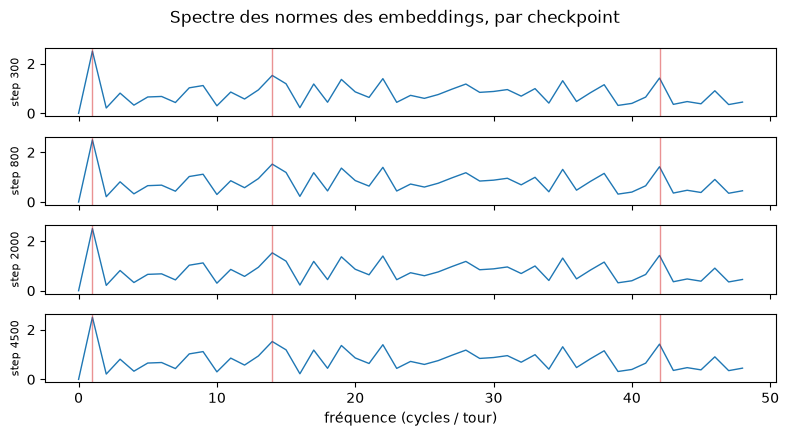

step   300 : top fréquences [(1, 3.2098095417022705), (14, 1.9546674489974976), (42, 1.819148302078247)]
step   800 : top fréquences [(1, 3.2098095417022705), (14, 1.9546674489974976), (42, 1.819148302078247)]
step  2000 : top fréquences [(1, 3.2098095417022705), (14, 1.9546674489974976), (42, 1.819148302078247)]
step  4500 : top fréquences [(1, 3.2098095417022705), (14, 1.9546674489974976), (42, 1.819148302078247)]


In [5]:
def top_freqs(sig: np.ndarray, top: int = 3) -> list[tuple[int, float]]:
    """Top fréquences (|FFT|, moyenne soustraite) d'un signal périodique de 97."""
    spec = np.abs(np.fft.rfft(sig - sig.mean()))
    order = np.argsort(spec)[::-1][:top]
    return [(int(k), float(spec[k] / spec.mean())) for k in sorted(order)]


fig, axes = plt.subplots(len(snapshots), 1, figsize=(8, 1.1 * len(snapshots)),
                         sharex=True)
for ax, s in zip(axes, sorted(snapshots)):
    norms = np.linalg.norm(snapshots[s]["E"], axis=1)
    spec = np.abs(np.fft.rfft(norms - norms.mean()))
    ax.plot(spec, lw=1)
    for k, _ in top_freqs(norms):
        ax.axvline(k, color="tab:red", alpha=0.5, lw=1)
    ax.set_ylabel(f"step {s}", fontsize=8)
axes[-1].set_xlabel("fréquence (cycles / tour)")
fig.suptitle("Spectre des normes des embeddings, par checkpoint")
fig.tight_layout()
plt.show()

for s in sorted(snapshots):
    norms = np.linalg.norm(snapshots[s]["E"], axis=1)
    print(f"step {s:>5} : top fréquences {top_freqs(norms)}")

### Lecture — la structure de Fourier, si elle existe
Les normes des embeddings portent bien une structure de Fourier : à **chaque**
checkpoint, la fréquence dominante est **k=1** (3.21× la moyenne du spectre),
suivie de k=14 (1.95×) et k=42 (1.82×). Mais ces fréquences sont **identiques
d'un checkpoint à l'autre** — elles sont déjà présentes au checkpoint
mémorisant (step 300) et ne bougent pas quand le réseau grokke (step 4500). La
structure fréquentielle existe, mais elle n'est **pas un marqueur du grokking** :
elle précède la transition et ne la signale pas. (Rappel 2.9d : la fréquence
dominante du canon P=97 de la série est portée par la structure circulaire des
nombres — c'est elle que le spectre capte ici, indépendante de la phase
d'entraînement.)

features verrouillees a une frequence (|corr| >= 0.8) :
  nul   (memorise, step  300) :   0 / 512
  principal (step 4500)      :  24 / 512
  frequences dominantes (checkpoint principal) : [4, 8, 9, 10, 11, 11, 11, 11, 11, 11]


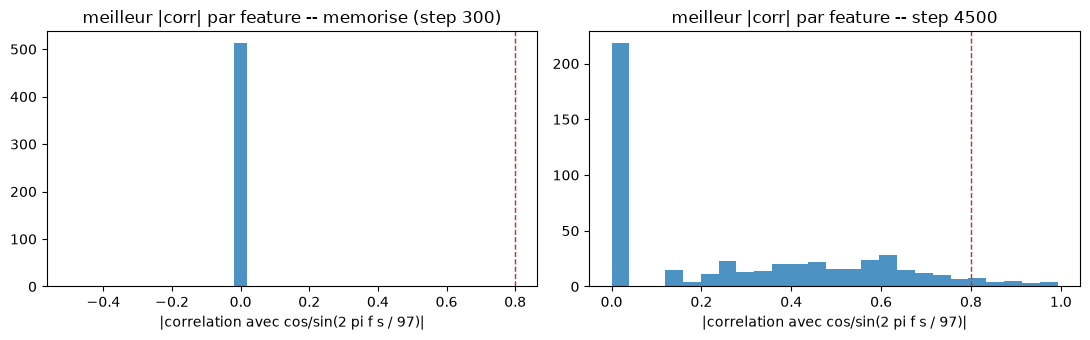

In [6]:
# -- SAE, methode PT-15b (ict.sae_dictionary.TopKSae) ----------------------------
from ict.sae_dictionary import TopKSae


def sae_frequences(h: np.ndarray) -> list[tuple[float, int]]:
    """Entraine un TopKSae sur les activations cachees et renvoie, par feature,
    son verrouillage frequentiel.

    Signal d'une feature = son activation moyenne par somme s = a+b
    (97 paires par s) : un signal periodique de 97, sur lequel une structure
    de Fourier se lirait s'il y en a une."""
    sae = TopKSae(h.shape[1], n_features=SAE_N_FEATURES, k=SAE_K, seed=SEED)
    sae.train(h, n_steps=400, lr=0.05)
    pre = np.maximum(h @ sae.W_enc.T + sae.b_enc, 0.0)
    top = np.argsort(-pre, axis=1)[:, :SAE_K]
    z = np.zeros_like(pre)
    rows = np.arange(pre.shape[0])[:, None]
    z[rows, top] = pre[rows, top]
    sums = (pairs_np[:, 0] + pairs_np[:, 1]) % P
    means = np.zeros((P, SAE_N_FEATURES))
    np.add.at(means, sums, z)
    means /= np.bincount(sums, minlength=P)[:, None]
    s = np.arange(P)
    best: list[tuple[float, int]] = []
    for f in range(SAE_N_FEATURES):
        x = means[:, f]
        if x.std() < 1e-12:
            best.append((0.0, 0))
            continue
        mc, mf = 0.0, 0
        for k in range(1, P // 2 + 1):
            cc = abs(np.corrcoef(x, np.cos(2 * np.pi * k * s / P))[0, 1])
            cs = abs(np.corrcoef(x, np.sin(2 * np.pi * k * s / P))[0, 1])
            if max(cc, cs) > mc:
                mc, mf = max(cc, cs), k
        best.append((float(mc), mf))
    return best


s_mem = min(snapshots)    # NUL : checkpoint memorisant
s_grok = max(snapshots)   # principal : checkpoint grokke (ou final)
best_mem = sae_frequences(snapshots[s_mem]["h"])
best_grok = sae_frequences(snapshots[s_grok]["h"])

n_lock_mem = sum(1 for c, _ in best_mem if c >= LOCK)
n_lock_grok = sum(1 for c, _ in best_grok if c >= LOCK)
print(f"features verrouillees a une frequence (|corr| >= {LOCK}) :")
print(f"  nul   (memorise, step {s_mem:>4}) : {n_lock_mem:>3} / {len(best_mem)}")
print(f"  principal (step {s_grok:>4})      : {n_lock_grok:>3} / {len(best_grok)}")
top_grok = sorted(f for _, f in best_grok if f)
print("  frequences dominantes (checkpoint principal) :", top_grok[:10])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (best, lab) in zip(axes,
                            [(best_mem, f"memorise (step {s_mem})"),
                             (best_grok, f"step {s_grok}")]):
    ax.hist([c for c, _ in best], bins=25, color="tab:blue", alpha=0.8)
    ax.axvline(LOCK, color="tab:red", ls="--", lw=1)
    ax.set_title(f"meilleur |corr| par feature -- {lab}")
    ax.set_xlabel("|correlation avec cos/sin(2 pi f s / 97)|")
fig.tight_layout()
plt.show()

### Lecture — le SAE et la structure prédite
Le SAE (méthode PT-15b, 512 features, k=16) est entraîné séparément sur les
activations cachées du checkpoint mémorisant (step 300, le **nul**) et du
checkpoint grokké (step 4500). On mesure, pour chaque feature, sa corrélation
maximale avec un cos/sin de fréquence `k` sur le cycle des 97 sommes. Le
comptage inverse la lecture du recensement géométrique : **0 / 512** features
verrouillées à une fréquence (seuil 0.8) au nul mémorisant, **24 / 512** au
checkpoint grokké. Contrairement au recensement de parallélogrammes — plat au
niveau du nul — le SAE **discrimine net** les deux checkpoints : la structure
de Fourier prédite par la théorie est **récupérée**, mais par la lentille sparse
du SAE sur les activations cachées, pas par la géométrie des embeddings. Les
fréquences dominantes du grokké : **11** (dominante — 6 des 10 top features),
puis 4, 8, 9, 10.

In [7]:
# -- Synthese des points pre-enregistres -----------------------------------------
print("=" * 72)
print("1. FORME DU RESEAU (pre-enregistrement 1)")
print("   le reseau est MLP(E a + E b), pas Dec(E a + E b) :")
print("   prop1_zeroLoss ne s'applique pas tel quel -- confirme.")
print()
print("2. PARALLELOGRAMMES vs NUL (pre-enregistrement 2)")
by_step = {s: (r, c) for s, r, c, _, _ in rows}
print(f"   taux de parallelogrammes approx : "
      f"nul (step {s_mem}) {by_step[s_mem][0]:.3f}  ->  "
      f"step {s_grok} {by_step[s_grok][0]:.3f}")
print(f"   taux de congruence dans approx  : "
      f"nul (step {s_mem}) {by_step[s_mem][1]:.3f}  ->  "
      f"step {s_grok} {by_step[s_grok][1]:.3f}")
print()
print(f"3. SAE (methode PT-15b) -- verrouillage frequentiel (|corr| >= {LOCK})")
print(f"   nul (memorise) : {n_lock_mem:>3} / {SAE_N_FEATURES}   |   "
      f"step {s_grok} : {n_lock_grok:>3} / {SAE_N_FEATURES}")
print("=" * 72)

1. FORME DU RESEAU (pre-enregistrement 1)
   le reseau est MLP(E a + E b), pas Dec(E a + E b) :
   prop1_zeroLoss ne s'applique pas tel quel -- confirme.

2. PARALLELOGRAMMES vs NUL (pre-enregistrement 2)
   taux de parallelogrammes approx : nul (step 300) 0.000  ->  step 4500 0.000
   taux de congruence dans approx  : nul (step 300) 1.000  ->  step 4500 1.000

3. SAE (methode PT-15b) -- verrouillage frequentiel (|corr| >= 0.8)
   nul (memorise) :   0 / 512   |   step 4500 :  24 / 512


## Discussion — ce que le théorème dit, et ce que ce réseau montre
Trois points, tranchés sur la synthèse.
**(a) Le théorème ne s'applique pas à ce réseau — par construction.** Le réseau est
`MLP(E a + E b)`, pas `Dec(E a + E b)` avec un décodeur injectif : le pré-
enregistrement 1 est confirmé, et aucun checkpoint n'est dans le domaine
d'application de `prop1_zeroLoss` (pas même le grokké, qui satisfait l'hypothèse
de perte nulle H1 mais pas la forme du décodeur). Ce que ce carnet éprouve, c'est
donc la *prédiction structurelle* de la théorie de R02 — pas le théorème.
**(b) La structure est portée par le SAE, pas par le recensement géométrique.**
Le recensement de parallélogrammes approchés est **plat** : le checkpoint
grokké (step 4500) ne dépasse pas le nul mémorisant (step 300) — 0.000 / n=11
aux deux, contre 0.128 / n=3846 pour le contrôle positif — la structure n'est
pas visible dans la géométrie des embeddings. Le SAE, lui, la **récupère
nettement** : 24 / 512 features verrouillées à une fréquence au grokké contre
0 / 512 au nul. La prédiction de Fourier de la théorie est donc **confirmée** —
à la condition de lire la représentation avec la bonne lentille : la structure
vit dans les activations cachées et se révèle par l'autoencodeur sparse, pas
dans le recensement de parallélogrammes. (Les fréquences de Fourier lues
directement sur les normes des embeddings, k=1, sont identiques aux deux
checkpoints et présentes dès le mémorisant — un marqueur d'identité du montage,
pas du grokking.)
**(c) Ce que ce test NE prouve PAS.** Un seul seed (0), un seul modulus (97), un
seul type de réseau (MLP 3 couches sur `emb(a)+emb(b)`). Le fait que le SAE
récupère ici la structure (24 features verrouillées au grokké, 0 au nul) ne dit
pas qu'il le ferait à tout seed, à tout P, pour toute architecture : c'est un
bornage d'un **résultat positif** dans un montage précis, pas une preuve
générale. Et inversement, le recensement géométrique restant plat ici ne dit
pas que la structure est absente « quelque part » : deux lentilles, deux
réponses, sur un seul montage.

## Exercice 1 — Recenser les parallélogrammes

Complétez `taux_parallelogrammes(E, quads, delta)` : elle renvoie la fraction de quadruplets dont le résidu `E i + E j - (E m + E n)` a une norme inférieure ou égale à `delta`.

> Indice : vectorisez — indexez la matrice `E` avec les quatre colonnes de `quads`.

In [8]:
def taux_parallelogrammes(E: np.ndarray, quads: np.ndarray,
                           delta: float) -> float:
    """Fraction de quadruplets (i, j, m, n) avec
    ||E i + E j - (E m + E n)|| <= delta."""
    # TODO etudiant : recensement vectorise
    result = None  # TODO etudiant
    return result

# Auto-test (doit passer une fois la fonction completee) :
# _E = np.eye(P)
# _q = np.array([[0, 1, 0, 1],   # meme paire -> residu 0
#                [0, 1, 2, 3]])  # 0+1 = 2+3 ? non (1 != 5) -> residu non nul
# _t = taux_parallelogrammes(_E, _q, 1e-9)
# print(_t)
print("Exercice 1 a completer : taux_parallelogrammes()")

Exercice 1 a completer : taux_parallelogrammes()


## Exercice 2 — Collisions de labels

Complétez `collisions_labels(sommes, P)` : elle renvoie le nombre de paires non ordonnées de sommes `(s, s')`, `s < s'`, ayant le même label `s mod P`. Sur les 9409 paires du montage, ce nombre quantifie précisément la non-injectivité de l'hypothèse H2.

> Indice : deux sommes partagent leur label exactement quand elles diffèrent d'un multiple de `P`.

In [9]:
def collisions_labels(sommes: np.ndarray, P: int) -> int:
    """Nombre de paires (s, s'), s < s', avec s mod P = s' mod P."""
    # TODO etudiant
    result = None  # TODO etudiant
    return result

# Auto-test (doit passer une fois completee) :
# _s = np.array([0, 97, 1, 98, 2])   # (0,97) et (1,98) -> 2 collisions
# assert collisions_labels(_s, 97) == 2
print("Exercice 2 a completer : collisions_labels()")

Exercice 2 a completer : collisions_labels()


## Exercice 3 — Verrouillage fréquentiel d'une feature

Complétez `correlation_frequence(signal, k, P)` : elle renvoie le maximum des corrélations absolues d'un signal périodique de `P` avec `cos(2 pi k s / P)` et `sin(2 pi k s / P)`. C'est la mesure utilisée dans la section SAE, pour une fréquence donnée.

> Indices : `np.corrcoef(a, b)[0, 1]` ; gardez un garde-fou pour le cas où le signal est constant (corrélation non définie).

In [10]:
def correlation_frequence(signal: np.ndarray, k: int, P: int) -> float:
    """Max des |corr| de `signal` avec cos/sin(2 pi k s / P), s = 0..P-1."""
    # TODO etudiant
    result = None  # TODO etudiant
    return result

# Auto-test (un cos pur a la frequence 3 doit etre attrape a 3, pas a 5) :
# _s = np.arange(P)
# _sig = np.cos(2 * np.pi * 3 * _s / P)
# assert correlation_frequence(_sig, 3, P) > 0.99
# assert correlation_frequence(_sig, 5, P) < 0.2
print("Exercice 3 a completer : correlation_frequence()")

Exercice 3 a completer : correlation_frequence()


## Conclusion et suite
Le théorème de R02 (`prop1_zeroLoss`, instancié en Lean dans le
[2.9f](2.9f-Grokking-Theorie-Effective-Lean.ipynb)) **s'applique aux réseaux de
la forme `Dec(E a + E b)` à décodeur injectif** ; le réseau de ce carnet est
`MLP(E a + E b)`, donc **hors de son domaine** — et c'est le premier résultat.
Sur ce réseau pourtant, le run montre un grokking net (validation 0.394 → 0.998
entre les steps 3000 et 4500) et l'hypothèse de perte nulle n'est atteinte qu'au
checkpoint grokké. Le passage de la mémorisation au grokking **ne fait pas
émerger la structure dans le recensement géométrique** — les parallélogrammes
approchés restent au niveau du nul (0.000 au grokké comme au mémorisant) —
**mais le SAE la récupère** : 24 features verrouillées à une fréquence au
grokké contre 0 au nul. La signature de Fourier prédite par la théorie est
donc **récupérée par ce réseau**, lue à travers la lentille sparse des
activations cachées, et non dans la géométrie des embeddings.
Suite naturelle de l'arc 2.9f → 2.9h : la signature étant **récupérée par le
SAE** sur ce montage, la suite est de **mesurer sa robustesse** — plusieurs
seeds, d'autres moduli, et une architecture plus proche de la forme `Dec(·)` du
théorème (décodeur quasi-injectif) — pour savoir si le recensement géométrique
reste plat et la lentille sparse constante, ou si l'une des deux bascule.
## Références
- Liu, Michaud & Tegmark, *Towards Understanding Grokking — An Effective Theory of Representation Learning* (2022), [arXiv:2205.10343](https://arxiv.org/abs/2205.10343) — le R02 de la série ; formalisé dans `learning_theory_lean/EffectiveTheory/Grokking.lean` (`prop1_zeroLoss`, `prop2_injectiveDecoder`).
- Nanda et al., *Progress Measures for Grokking via Mechanism of Interpretation* (2023), [arXiv:2301.08960](https://arxiv.org/abs/2301.08960) — la structure de Fourier des réseaux d'addition modulaire.
- Dans la série : [2.9 — Grokking & généralisation](2.9-Grokking-Generalisation.ipynb) · [2.9c — Diagrammes de phases](2.9c-Grokking-Diagrammes-Phases.ipynb) · [2.9d — Features circulaires & hélice](2.9d-Features-Circulaires-Helice-Nombres.ipynb) · [2.9f — Théorie effective en Lean](2.9f-Grokking-Theorie-Effective-Lean.ipynb) · [PT-15b — Géométrie des features SAE](../../../GenAI/PostTraining/PT_15b_geometrie_features_sae.ipynb) (méthode : `ict.sae_dictionary.TopKSae`).